In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


In [2]:
# construction du dataframe des features à partir des matchs. Prend bien en compte l'historique d'achat des items.
# features: champion, role, adversaire, item actuel, gold et next item (cible)

from matchup_analysis import build_feature_dataframe_from_parsed
df = build_feature_dataframe_from_parsed(parsed_folder="parsed_matches", champ_data_path="champ_data.csv")
df = df[df["Item actuel"] != df["Next item"]]

#df.to_csv("features_all_matches.csv", index=False, encoding="utf-8")

print(df.shape)
#df.head()
df.tail()



Récupération des données items via DataDragon...
(50941, 10)


,Champion,Classe du champion,Dégat du champion,Role,Adversaire,Classe de l'adversaire,Dégat de l'adversaire,Gold,Item actuel,Next item
52446,Tristana,Marksman,AD,BOTTOM,Kaisa,Marksman,Mixed,8488,Yun Tal Wildarrows,Infinity Edge
52447,Tristana,Marksman,AD,BOTTOM,Kaisa,Marksman,Mixed,11071,Infinity Edge,Navori Flickerblade
52448,Tristana,Marksman,AD,BOTTOM,Kaisa,Marksman,Mixed,13914,Navori Flickerblade,Lord Dominik's Regards
52449,TahmKench,Tank,AP,UTILITY,Nautilus,Tank,AP,4483,None,Thornmail
52450,TahmKench,Tank,AP,UTILITY,Nautilus,Tank,AP,7248,Thornmail,Unending Despair


In [35]:
# Nombre de classes différentes
num_classes = df['Next item'].nunique()
print(f"Nombre de classes différentes dans 'Next item' : {num_classes}")


Nombre de classes différentes dans 'Next item' : 107


In [27]:
filtered_df = df[df["Item actuel"] == df["Next item"]]
print(filtered_df.shape)
filtered_df.head()

(1510, 10)


,Champion,Classe du champion,Dégat du champion,Role,Adversaire,Classe de l'adversaire,Dégat de l'adversaire,Gold,Item actuel,Next item
95,Ezreal,Marksman,Mixed,BOTTOM,Kaisa,Marksman,Mixed,8550,Manamune,Manamune
115,Kassadin,Assassin,AP,MIDDLE,Quinn,Marksman,AD,10100,Archangel's Staff,Archangel's Staff
190,Kaisa,Marksman,Mixed,BOTTOM,Jhin,Marksman,AD,17760,Immortal Shieldbow,Immortal Shieldbow
290,Velkoz,Mage,AP,MIDDLE,Hwei,Mage,AP,3689,Stormsurge,Stormsurge
323,Vayne,Marksman,AD,BOTTOM,Caitlyn,Marksman,AD,10728,Wit's End,Wit's End


In [45]:
from matchup_analysis import build_feature_dataframe
df2 = build_feature_dataframe()
print(df2.shape)
df2.head()

# donne des beaucoups moins bon résultats que le df construit directement par l'historique. Les dimensions ne sont pas les memes non plus
# -> ne prend pas bien en compte l'historique et les lignes dupliquées

(36294, 7)


,Champion,Role,Adversaire,Dégat de l'adversaire,Gold,Item actuel,Next item
0,Aatrox,TOP,Renekton,AD,4589.3,NaN,Spear of Shojin
1,Aatrox,TOP,Mordekaiser,AP,4892.0,NaN,Spear of Shojin
2,Aatrox,TOP,Yone,AD,4591.0,NaN,Eclipse
3,Aatrox,TOP,Renekton,AD,7422.5,Spear of Shojin,Voltaic Cyclosword
4,Aatrox,TOP,Sion,AD,3962.0,NaN,Eclipse


C:\Users\preda\AppData\Local\Temp\ipykernel_10524\1002222315.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis')


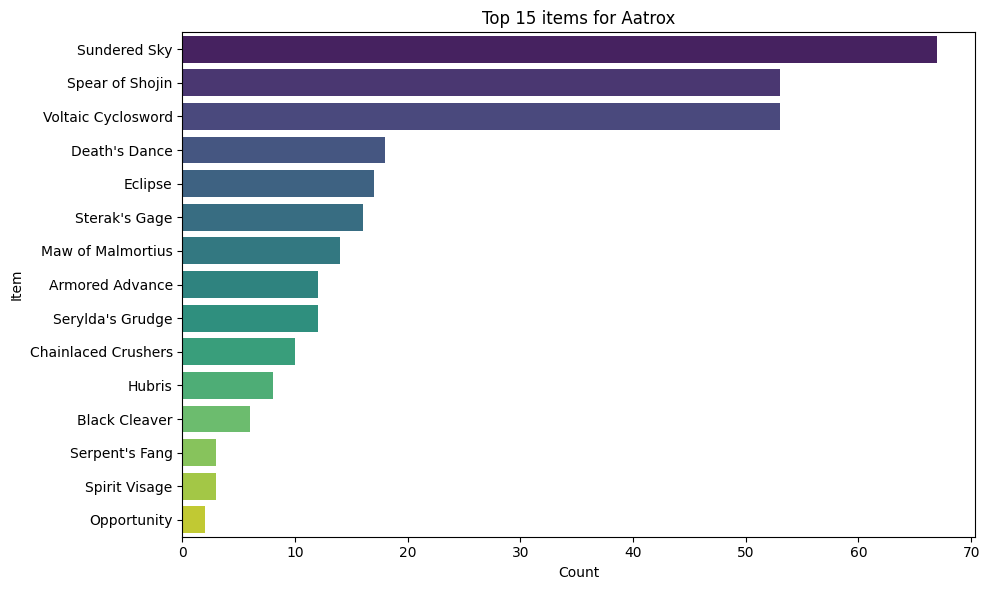

In [3]:
# Fonction de visualisation des top-N items
def plot_top_items(df, champion=None, topn=20, column='Next item'):
    """
    Bar plot des top-N items (globaux ou filtrés par champion).
    """
    sub = df if champion is None else df[df['Champion'] == champion]
    counts = sub[column].value_counts().nlargest(topn)
    plt.figure(figsize=(10,6))
    sns.barplot(x=counts.values, y=counts.index, palette='viridis')
    plt.xlabel('Count')
    plt.ylabel('Item')
    title = f"Top {topn} items"
    if champion: title += f" for {champion}"
    plt.title(title)
    plt.tight_layout()

# Example:
plot_top_items(df, champion='Aatrox', topn=15)

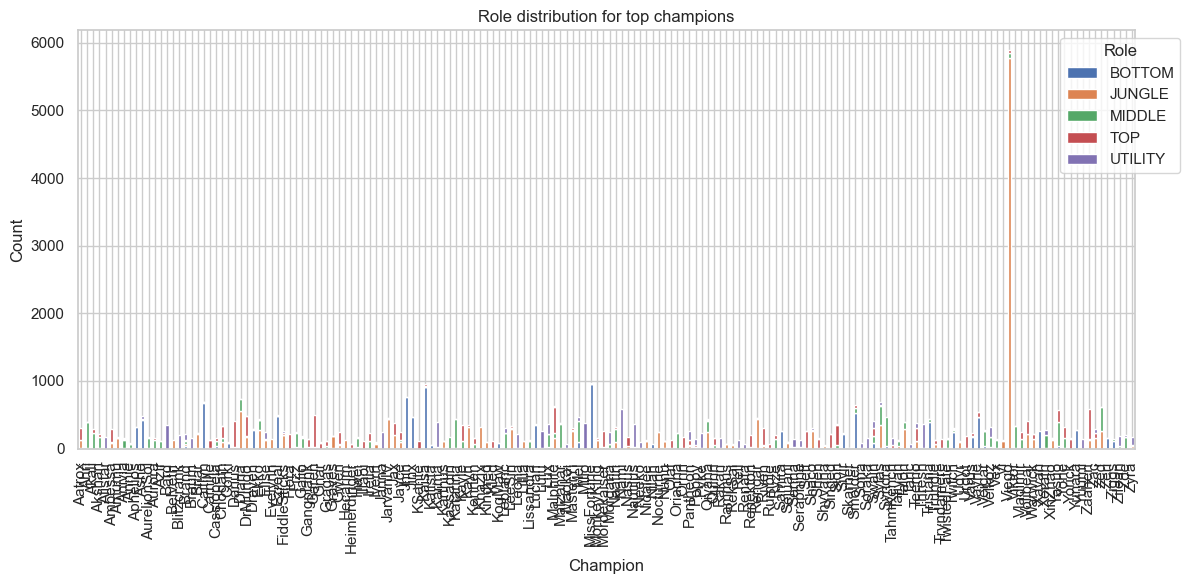

In [30]:
# permet de voir comment se répartissent les rôles pour les champions les plus joués 
# (beaucoup d'adc car peu de champions en bottom et wtf viego)
def plot_role_distribution(df, champion=None, topn=10):
    """
    Affiche la distribution des rôles pour les champions les plus fréquents
    ou pour un champion donné.
    """
    if champion:
        pivot = df[df['Champion'] == champion].groupby('Role')['Next item'].count().sort_values(ascending=False)
        pivot.plot(kind='bar', figsize=(6,4))
        plt.title(f"Role distribution for {champion}")
        plt.ylabel('Count')
    else:
        top_champs = df['Champion'].value_counts().nlargest(topn).index
        sub = df[df['Champion'].isin(top_champs)]
        pivot = sub.groupby(['Champion','Role']).size().unstack(fill_value=0)
        pivot.plot(kind='bar', stacked=True, figsize=(12,6))
        plt.title("Role distribution for top champions")
        plt.ylabel('Count')
        plt.legend(title='Role', bbox_to_anchor=(1.05,1))
    plt.tight_layout()

# Example:
plot_role_distribution(df, topn=173)
# plot_role_distribution(df, champion='Aatrox')

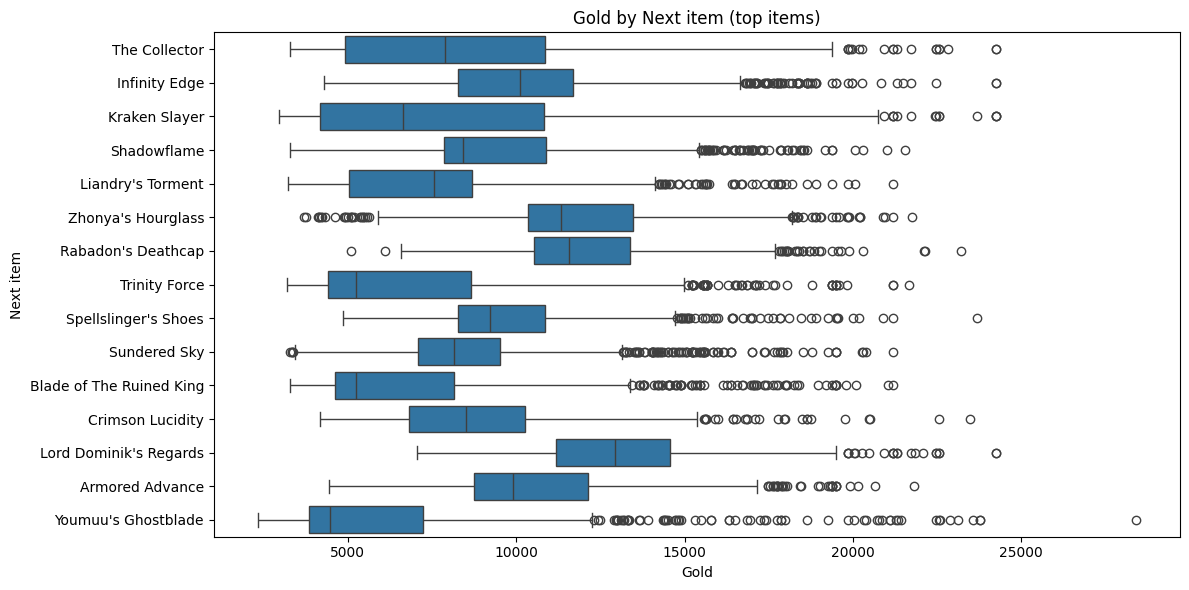

In [4]:
# permet de voir quand sont achetés les items (au début avec les premiers golds ou à la fin)
def plot_gold_by_item(df, item_col='Next item', topn=20):
    top_items = df[item_col].value_counts().nlargest(topn).index
    sub = df[df[item_col].isin(top_items)]
    plt.figure(figsize=(12,6))
    sns.boxplot(y=item_col, x='Gold', data=sub, order=top_items)
    plt.title('Gold by Next item (top items)')
    plt.tight_layout()

# Example:
plot_gold_by_item(df, topn=15)

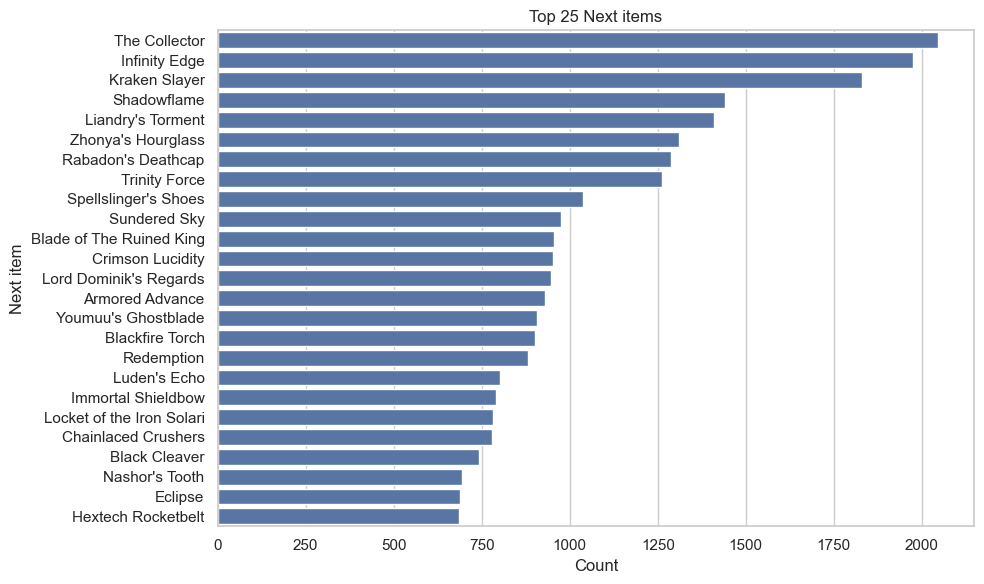

In [31]:
# voir la popularité des items achetés
def plot_next_item_counts(df, topn=30):
    counts = df['Next item'].value_counts().nlargest(topn)
    plt.figure(figsize=(10,6))
    sns.barplot(x=counts.values, y=counts.index)
    plt.title(f'Top {topn} Next items')
    plt.xlabel('Count')
    plt.tight_layout()

# Example:
plot_next_item_counts(df, topn=25)

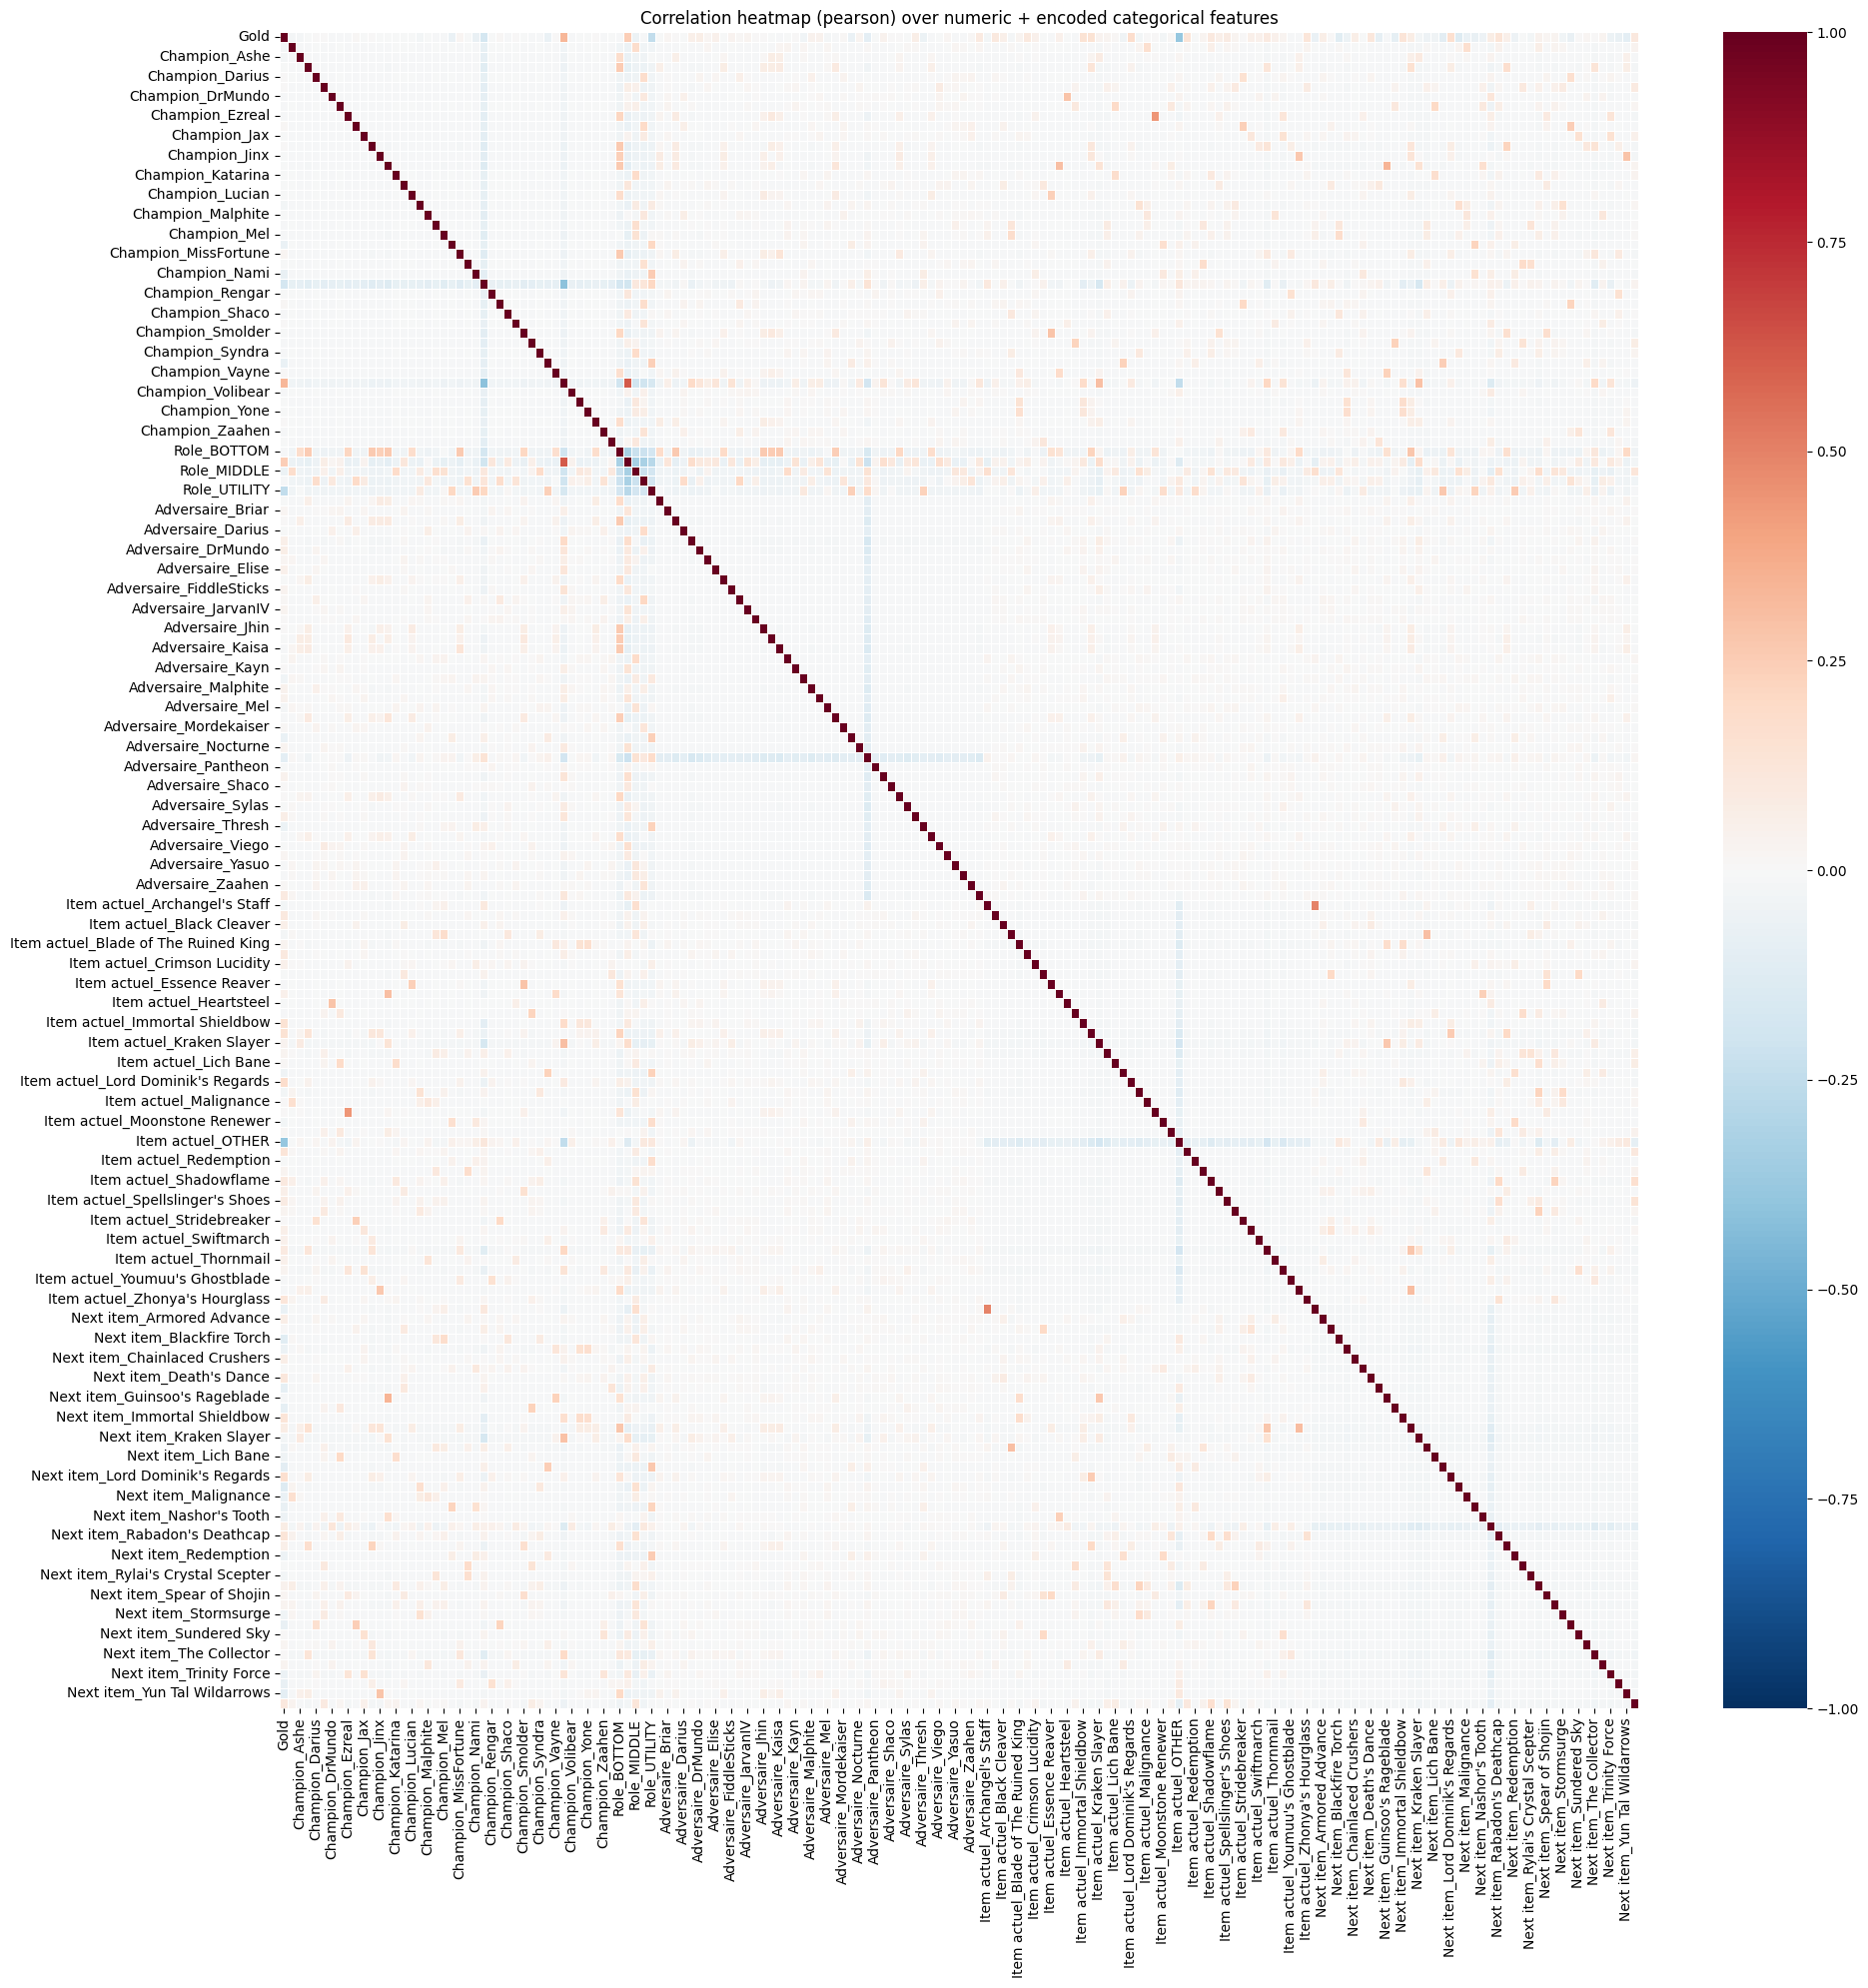

In [3]:
# pas fou, on peut voir une corrélation entre manamune et ez par exemple, mais bcp trop grand pour l'instant

def plot_correlation_heatmap(df, categorical_cols=None, numeric_cols=None, encode='onehot', method='pearson', topk_categories=50):
    """
    - encode: 'onehot' ou 'label'
    - method: 'pearson' or 'spearman'
    - topk_categories: si onehot, garder top-K valeurs par catégorie (remplacer le reste par 'OTHER') pour éviter explosion
    """
    df = df.copy()

    if numeric_cols is None:
        # essayer de détecter colonnes numériques
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    if categorical_cols is None:
        categorical_cols = [c for c in df.columns if c not in numeric_cols]

    # Prepare categorical subset
    cat_df = pd.DataFrame(index=df.index)
    for c in categorical_cols:
        if encode == 'onehot':
            # reduce cardinality
            top_vals = df[c].value_counts().nlargest(topk_categories).index
            series = df[c].where(df[c].isin(top_vals), other='OTHER').fillna('UNKNOWN')
            dummies = pd.get_dummies(series, prefix=c)
            cat_df = pd.concat([cat_df, dummies], axis=1)
        else:  # label
            series = df[c].fillna('UNKNOWN').astype(str)
            le = pd.factorize(series)[0]  # faster than sklearn for quick viz
            cat_df[c] = le

    num_df = df[numeric_cols].copy()

    # combine
    combined = pd.concat([num_df, cat_df], axis=1).fillna(0)

    # compute correlation matrix
    corr = combined.corr(method=method)

    # plot heatmap (size driven by number of columns)
    plt.figure(figsize=(min(20, 0.25*corr.shape[0]), min(20, 0.25*corr.shape[1])))
    sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=.5)
    plt.title(f'Correlation heatmap ({method}) over numeric + encoded categorical features')
    plt.tight_layout()

# Example:
plot_correlation_heatmap(df, categorical_cols=['Champion','Role','Adversaire','Item actuel','Next item'], numeric_cols=['Gold'], encode='onehot', method='pearson', topk_categories=40)

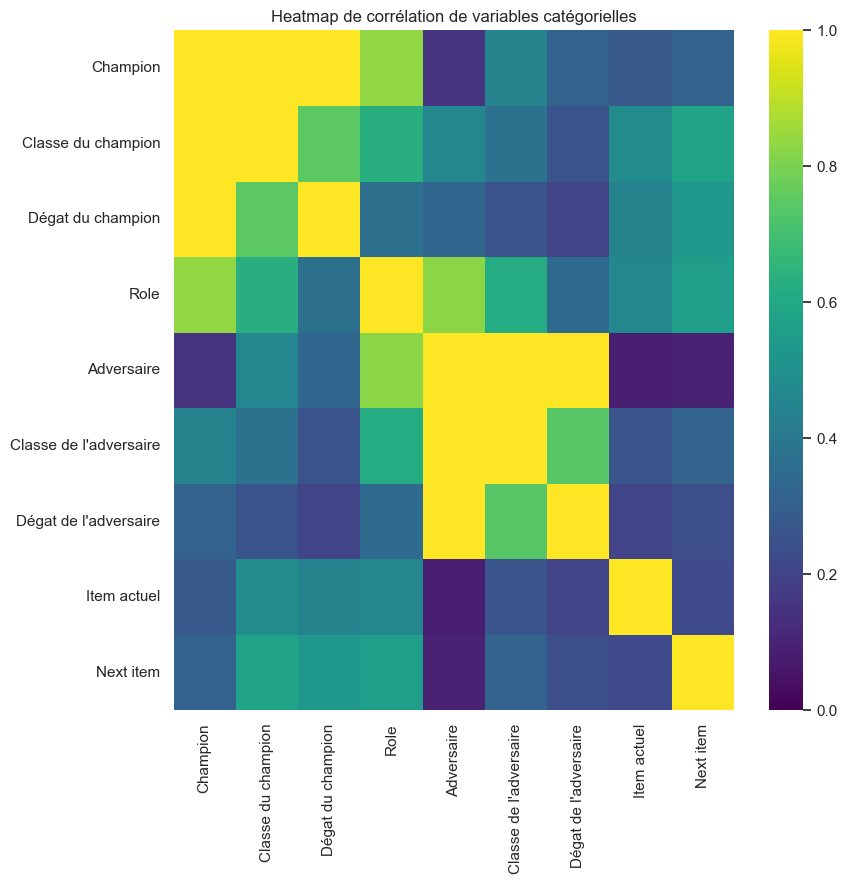

In [32]:
import scipy.stats as ss

#Heatmap de corrélation de variables catégorielles
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = ss.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r,k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1),(rcorr-1)+1e-9))

def category_heatmap(df, cats, topk=30):
    cats = list(cats)
    m = np.zeros((len(cats), len(cats)))
    for i,a in enumerate(cats):
        for j,b in enumerate(cats):
            m[i,j] = cramers_v(df[a].fillna('NA'), df[b].fillna('NA'))
    plt.figure(figsize=(len(cats), len(cats)))
    sns.heatmap(m, xticklabels=cats, yticklabels=cats, cmap='viridis', vmin=0, vmax=1)
    plt.title("Heatmap de corrélation de variables catégorielles")
    plt.tight_layout()

# Example:
category_heatmap(df, ['Champion','Classe du champion', 'Dégat du champion', 'Role', 'Adversaire', 'Classe de l\'adversaire', 'Dégat de l\'adversaire','Item actuel', 'Next item'], topk=30)

C:\Users\preda\AppData\Local\Temp\ipykernel_24524\1822901584.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Index(['Kraken Slayer', 'The Collector', 'Infinity Edge', 'Trinity Force',
       'Liandry's Torment', 'Shadowflame', 'Blade of The Ruined King',
       'Youmuu's Ghostblade', 'Blackfire Torch', 'Sundered Sky'],
      dtype='object', name='Item actuel')


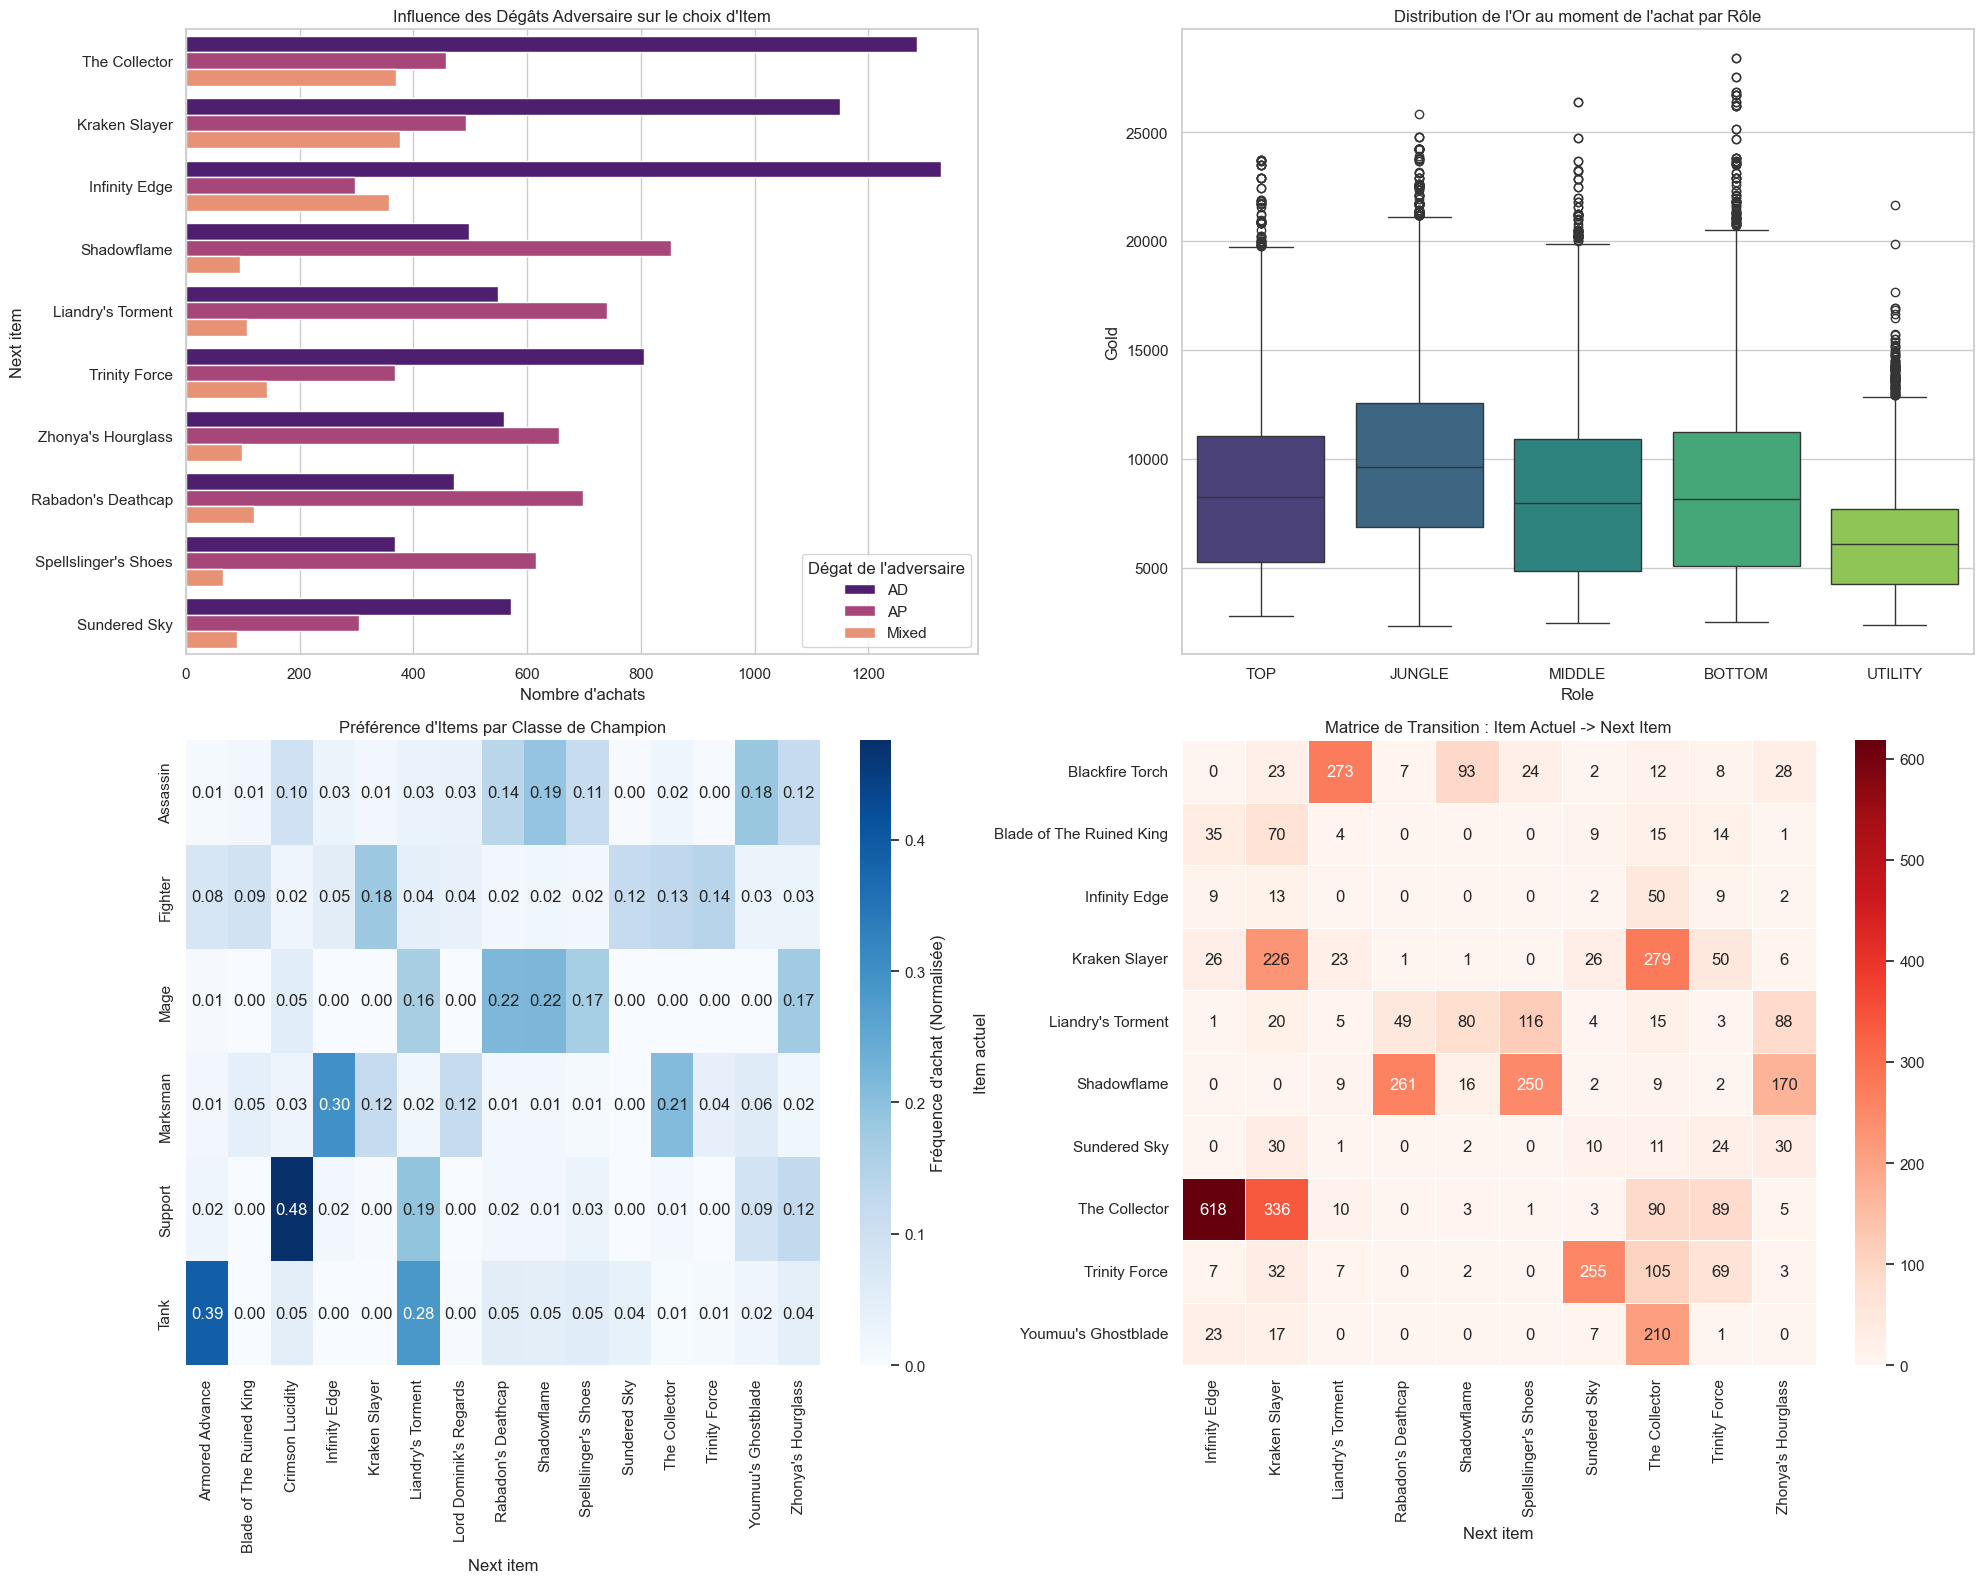

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configuration du style
sns.set_theme(style="whitegrid")

def plot_advanced_eda(df):
    """
    Génère 4 graphiques avancés pour comprendre les relations entre features.
    """
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    
    # --- 1. Counter-Building : Top Items selon les Dégâts de l'Adversaire ---
    # On prend les 10 items les plus fréquents pour ne pas surcharger le graphe
    top_items = df['Next item'].value_counts().nlargest(10).index
    df_top = df[df['Next item'].isin(top_items)]
    
    sns.countplot(
        data=df_top, 
        y='Next item', 
        hue='Dégat de l\'adversaire', 
        order=top_items,
        ax=axes[0, 0],
        palette="magma"
    )
    axes[0, 0].set_title("Influence des Dégâts Adversaire sur le choix d'Item")
    axes[0, 0].set_xlabel("Nombre d'achats")

    # --- 2. Distribution de l'Or par Rôle ---
    sns.boxplot(
        data=df, 
        x='Role', 
        y='Gold', 
        ax=axes[0, 1],
        palette="viridis"
    )
    axes[0, 1].set_title("Distribution de l'Or au moment de l'achat par Rôle")
    
    # --- 3. Heatmap : Classe du Champion vs Items (Normalisée) ---
    # On regarde les items fréquents croisés avec les classes
    top_items_heatmap = df['Next item'].value_counts().nlargest(15).index
    df_heatmap = df[df['Next item'].isin(top_items_heatmap)]
    
    # Création de la matrice de contingence (normalisée par ligne pour voir les préférences par classe)
    crosstab = pd.crosstab(df_heatmap['Classe du champion'], df_heatmap['Next item'])
    crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)
    
    sns.heatmap(
        crosstab_norm, 
        annot=True, 
        fmt=".2f", 
        cmap="Blues", 
        ax=axes[1, 0],
        cbar_kws={'label': 'Fréquence d\'achat (Normalisée)'}
    )
    axes[1, 0].set_title("Préférence d'Items par Classe de Champion")
    axes[1, 0].set_ylabel("")

    # --- 4. Matrice de Transition (Item Actuel -> Next Item) ---
    # On se concentre sur les items "Actuels" non nuls et fréquents
    valid_current = df['Item actuel'].value_counts().nlargest(10).index
    print(valid_current)
    # On exclut "None" si présent, ou on le garde pour voir le premier achat
    df_trans = df[df['Item actuel'].isin(valid_current) & df['Next item'].isin(top_items)]
    # Remplacer 'None' par un label plus clair dans une copie du dataframe
    df_trans_plot = df_trans.copy()
    df_trans_plot['Item actuel'] = df_trans_plot['Item actuel'].replace('None', 'Début / Composants')

    # Recalculer la matrice avec le nouveau nom
    trans_matrix = pd.crosstab(df_trans_plot['Item actuel'], df_trans_plot['Next item'])


    
    sns.heatmap(
        trans_matrix, 
        cmap="Reds", 
        linewidths=.5,
        ax=axes[1, 1],
        annot=True,    # <--- Ajoute les chiffres
        fmt="d"        # <--- Formate comme des entiers (pas de notation scientifique)
    )
    axes[1, 1].set_title("Matrice de Transition : Item Actuel -> Next Item")
    
    plt.tight_layout()
    plt.show()

# Lancer les visualisations
# Assurez-vous que 'df' est bien votre dataframe chargé
plot_advanced_eda(df)

In [ ]:
# On regarde les items fréquents croisés avec les classes
top_items_heatmap = df['Next item'].value_counts().nlargest().index
df_heatmap = df[df['Next item'].isin(top_items_heatmap)]

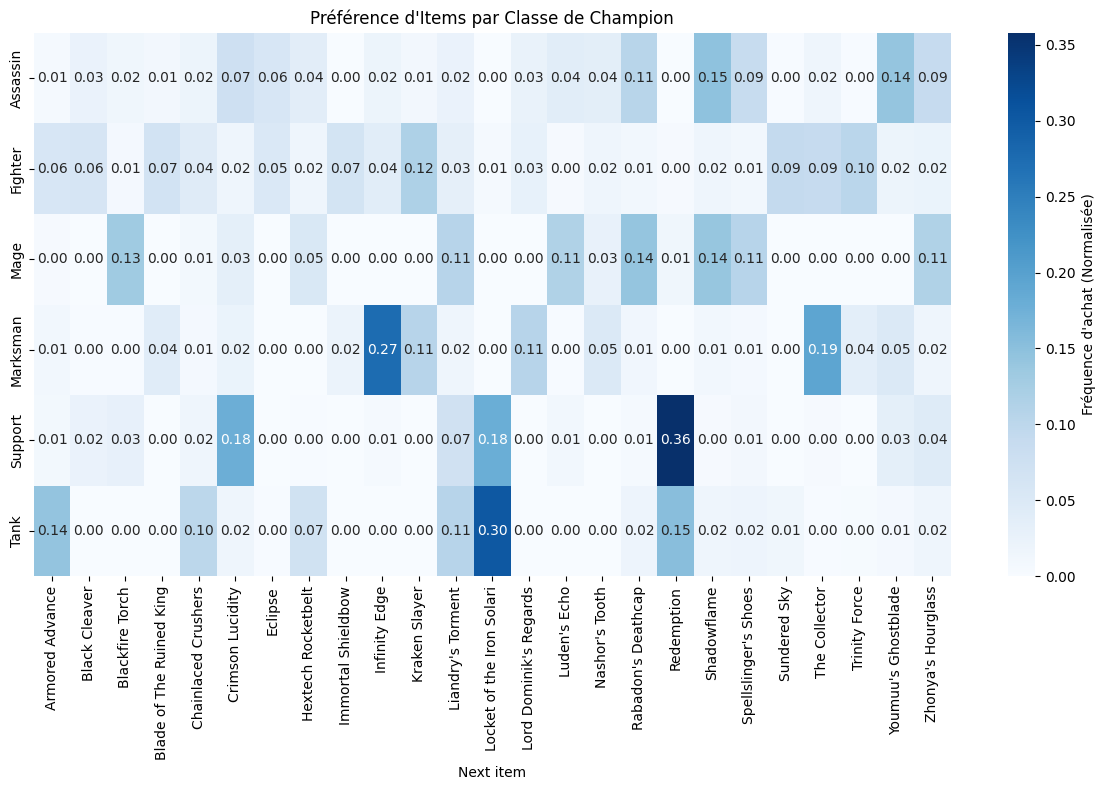

In [5]:
def plot_heatmap_classe_vs_items(df):
    # --- 3. Heatmap : Classe du Champion vs Items (Normalisée) ---
    top_items_heatmap = df['Next item'].value_counts().nlargest(25).index
    df_heatmap = df[df['Next item'].isin(top_items_heatmap)]

    crosstab = pd.crosstab(
        df_heatmap['Classe du champion'],
        df_heatmap['Next item']
    )
    crosstab_norm = crosstab.div(crosstab.sum(axis=1), axis=0)

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        crosstab_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        cbar_kws={'label': "Fréquence d'achat (Normalisée)"}
    )
    plt.title("Préférence d'Items par Classe de Champion")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
plot_heatmap_classe_vs_items(df)

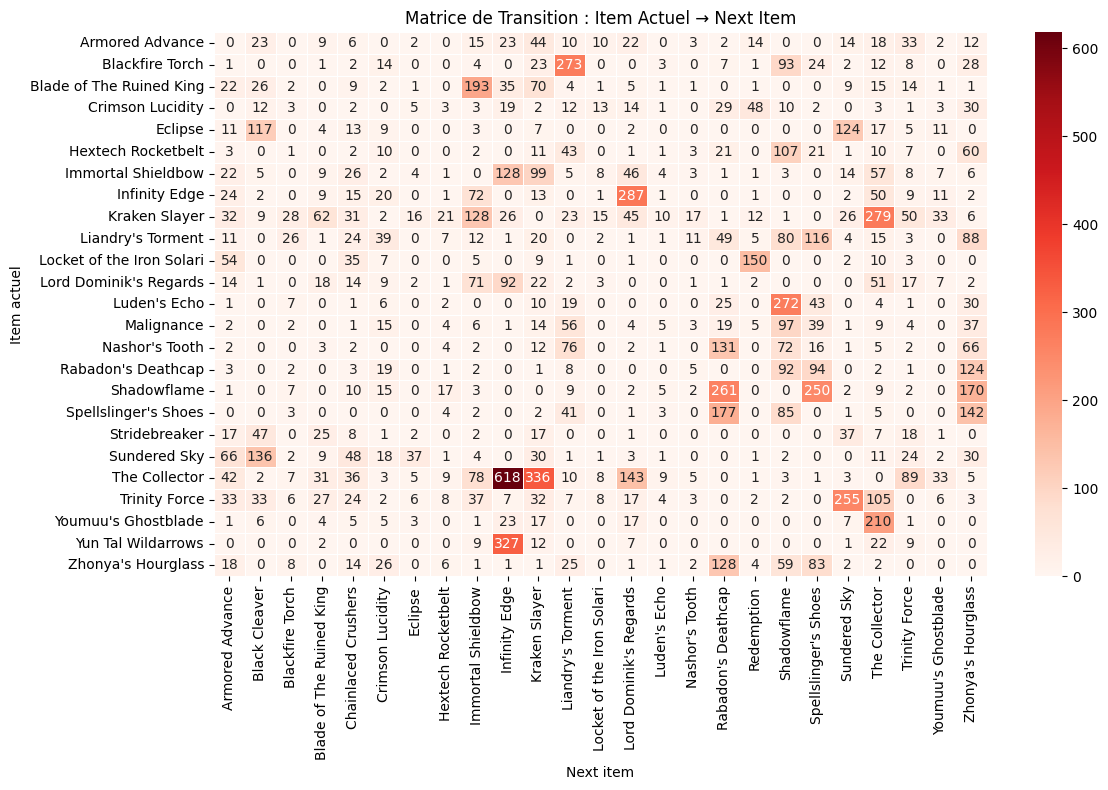

In [6]:
def plot_item_transition_matrix(df):
    # --- 4. Matrice de Transition ---
    valid_current = df['Item actuel'].value_counts().nlargest(25).index
    top_items = df['Next item'].value_counts().nlargest(25).index

    df_trans = df[
        df['Item actuel'].isin(valid_current) &
        df['Next item'].isin(top_items)
    ]

    df_trans_plot = df_trans.copy()
    df_trans_plot['Item actuel'] = df_trans_plot['Item actuel'].replace(
        'None', 'Début / Composants'
    )

    trans_matrix = pd.crosstab(
        df_trans_plot['Item actuel'],
        df_trans_plot['Next item']
    )

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        trans_matrix,
        cmap="Reds",
        linewidths=0.5,
        annot=True,
        fmt="d"
    )
    plt.title("Matrice de Transition : Item Actuel → Next Item")
    plt.tight_layout()
    plt.show()
plot_item_transition_matrix(df)

Comparaison entre ranks

In [7]:
df_iron = build_feature_dataframe_from_parsed("IRON", "champ_data.csv")
df_plat = build_feature_dataframe_from_parsed("PLAT", "champ_data.csv")
df_diam = build_feature_dataframe_from_parsed("DIAM", "champ_data.csv")


Récupération des données items via DataDragon...
Récupération des données items via DataDragon...
Récupération des données items via DataDragon...


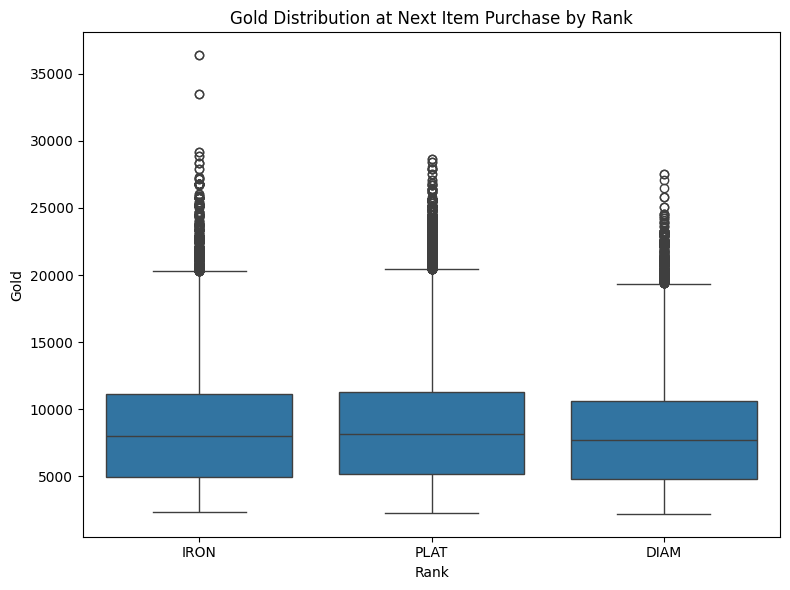

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_iron["Rank"] = "IRON"
df_plat["Rank"] = "PLAT"
df_diam["Rank"] = "DIAM"

df_all = pd.concat([df_iron, df_plat, df_diam])

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df_all,
    x="Rank",
    y="Gold"
)
plt.title("Gold Distribution at Next Item Purchase by Rank")
plt.tight_layout()
plt.show()


In [10]:
def plot_branching_factor(df, rank_name, top_n=15):
    branching = (
        df.groupby("Item actuel")["Next item"]
        .nunique()
        .sort_values(ascending=False)
        .head(top_n)
    )

    plt.figure(figsize=(10, 5))
    branching.plot(kind="bar")
    plt.title(f"Build Branching Factor by Item ({rank_name})")
    plt.ylabel("Number of distinct Next Items")
    plt.xlabel("Item actuel")
    plt.tight_layout()
    plt.show()
# Example:
#plot_branching_factor(df_iron, "IRON", top_n=15)
#plot_branching_factor(df_plat, "PLAT", top_n=15)
#plot_branching_factor(df_diam, "DIAM", top_n=15)

In [14]:
def plot_next_item_vs_enemy_class(df, rank_name, top_items=25):
    top_next_items = df["Next item"].value_counts().nlargest(top_items).index
    df_filt = df[df["Next item"].isin(top_next_items)]

    pivot = pd.crosstab(
        df_filt["Classe de l'adversaire"],
        df_filt["Next item"]
    )

    pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6)
    )
    plt.title(f"Next Item Distribution by Enemy Class ({rank_name})")
    plt.ylabel("Count")
    plt.xlabel("Enemy Class")
    plt.tight_layout()
    plt.show()

# Example:
#plot_next_item_vs_enemy_class(df_iron, "IRON")
#plot_next_item_vs_enemy_class(df_plat, "PLAT")
#plot_next_item_vs_enemy_class(df_diam, "DIAM")


C:\Users\preda\AppData\Local\Temp\ipykernel_10524\4126012524.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis', ax=ax)
C:\Users\preda\AppData\Local\Temp\ipykernel_10524\4126012524.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis', ax=ax)
C:\Users\preda\AppData\Local\Temp\ipykernel_10524\4126012524.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis', ax=ax)


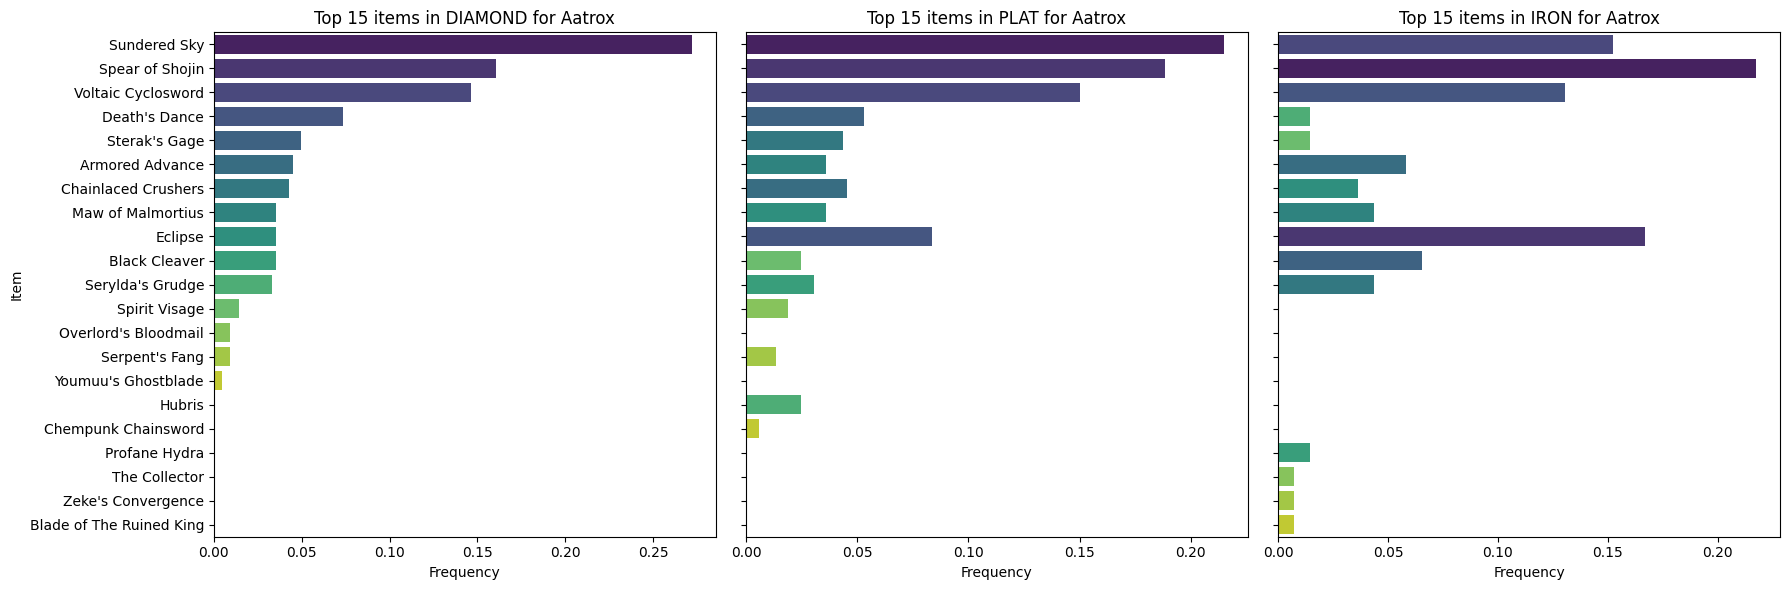

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_top_items_three_ranks(df_iron, df_plat, df_diam, champion=None, topn=20, column='Next item'):
    """
    Affiche les top-N items pour Iron, Plat et Diamond dans la même figure.
    """
    dfs = [("DIAMOND", df_diam), ("PLAT", df_plat), ("IRON", df_iron)]
    
    fig, axes = plt.subplots(1, 3, figsize=(18,6), sharey=True)
    
    for ax, (rank_name, df_rank) in zip(axes, dfs):
        sub = df_rank if champion is None else df_rank[df_rank['Champion'] == champion]
        if sub.empty:
            ax.set_title(f"No data for {rank_name}")
            ax.axis('off')
            continue
        
        counts = sub[column].value_counts(normalize=True).nlargest(topn)
        sns.barplot(x=counts.values, y=counts.index, palette='viridis', ax=ax)
        ax.set_xlabel('Frequency')
        ax.set_ylabel('Item' if ax==axes[0] else '')
        title = f"Top {topn} items in {rank_name}"
        if champion:
            title += f" for {champion}"
        ax.set_title(title)
    
    plt.tight_layout()
    plt.show()
# Example:
plot_top_items_three_ranks(df_iron, df_plat, df_diam,'Aatrox', topn=15, column='Next item')

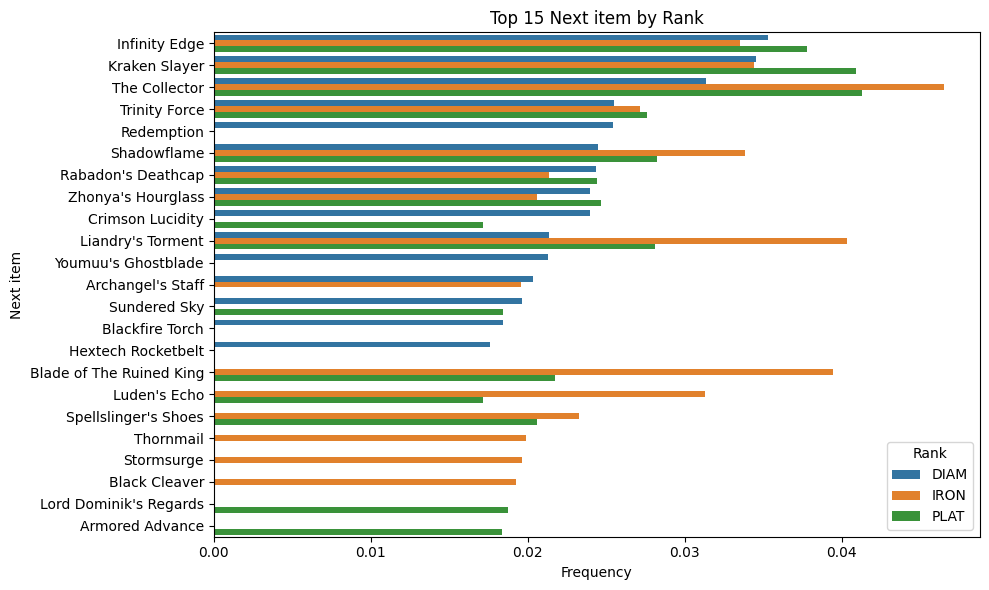

In [ ]:
def plot_top_items_comparative(df_iron, df_plat, df_diam, topn=20, column='Next item'):
    """
    Affiche un bar plot comparatif des top-N items pour les 3 ranks ensemble,
    en utilisant les fréquences relatives pour comparaison.
    """
    # Ajouter colonne Rank
    df_iron = df_iron.copy(); df_iron["Rank"] = "IRON"
    df_plat = df_plat.copy(); df_plat["Rank"] = "PLAT"
    df_diam = df_diam.copy(); df_diam["Rank"] = "DIAM"
    
    df_all = pd.concat([df_iron, df_plat, df_diam], ignore_index=True)
    
    # Calcul fréquence relative par rank
    df_freq = (
        df_all.groupby("Rank")[column]
        .value_counts(normalize=True)
        .rename("Frequency")
        .reset_index()
    )
    
    # Garder top-N items par rank
    top_items = df_freq.groupby("Rank").head(topn)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=top_items,
        x="Frequency",
        y=column,
        hue="Rank",
        dodge=True
    )
    plt.xlabel("Frequency")
    plt.ylabel(column)
    plt.title(f"Top {topn} {column} by Rank")
    plt.legend(title="Rank")
    plt.tight_layout()
    plt.show()
# Example:
plot_top_items_comparative(df_iron, df_plat, df_diam, topn=15, column='Next item')

C:\Users\preda\AppData\Local\Temp\ipykernel_10524\713189258.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_items.values, y=top_items.index, palette='magma')


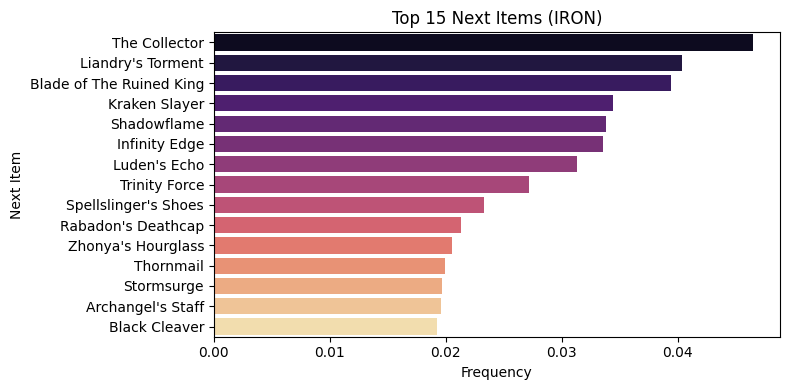

C:\Users\preda\AppData\Local\Temp\ipykernel_10524\713189258.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_items.values, y=top_items.index, palette='magma')


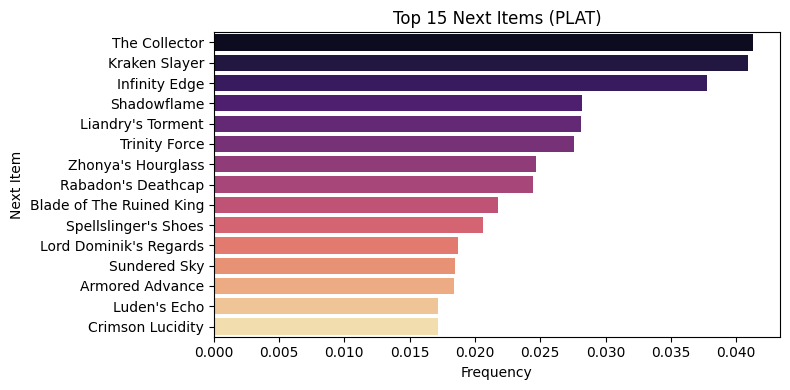

C:\Users\preda\AppData\Local\Temp\ipykernel_10524\713189258.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_items.values, y=top_items.index, palette='magma')


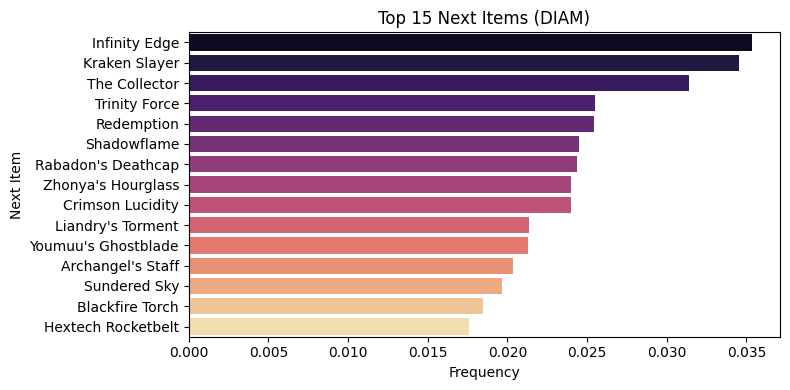

In [21]:
def plot_core_items(df, rank_name, top_n=10):
    """
    Bar plot des items les plus fréquents (next item) pour un rank donné.
    Utilise fréquences relatives pour comparaison entre ranks.
    """
    if df.empty:
        print(f"No data for {rank_name}")
        return

    top_items = df["Next item"].value_counts(normalize=True).nlargest(top_n)
    
    plt.figure(figsize=(8, 4))
    sns.barplot(x=top_items.values, y=top_items.index, palette='magma')
    plt.xlabel("Frequency")
    plt.ylabel("Next Item")
    plt.title(f"Top {top_n} Next Items ({rank_name})")
    plt.tight_layout()
    plt.show()

# Example:
plot_core_items(df_iron, "IRON", top_n=15)
plot_core_items(df_plat, "PLAT", top_n=15)
plot_core_items(df_diam, "DIAM", top_n=15)

Formulation du problème

Tâche : classification multi-classe — prédire 1 item parmi N (N = nombre d'items finals observés).

Entrée (contexte) possible : séquence d'items déjà achetés (ou uniquement dernier item), champion joué, champion adverse, rôle (lane), gold et possiblement plus

Sortie : probas sur le vocabulaire d'items; on utilise top-k accuracy (k=1,3,5) comme métriques principales.

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier

# Prépare les colonnes et nettoie les valeurs manquantes comme lors de l'entraînement
df = df.dropna(subset=["Next item"])
df['Item actuel'] = df['Item actuel'].fillna('None')
df['Role'] = df['Role'].fillna('Unknown')
df['Adversaire'] = df['Adversaire'].fillna('Unknown')

FEATURE_COLS = ['Champion','Classe du champion', 'Dégat du champion', 'Role', 'Adversaire', 'Classe de l\'adversaire', 'Dégat de l\'adversaire','Item actuel', 'Gold']
X = df[FEATURE_COLS]
y = df['Next item']

# encoder la cible
le_y = LabelEncoder()
y_enc = le_y.fit_transform(y)
print("Nombre de classes (items):", len(le_y.classes_))

# encoder catégoriels + scaler numérique (compatible scikit-learn versions)
categorical_cols = ['Champion','Classe du champion', 'Dégat du champion', 'Role', 'Adversaire', 'Classe de l\'adversaire', 'Dégat de l\'adversaire','Item actuel']
#categorical_cols = ['Champion', 'Role', 'Adversaire', 'Item actuel']  #anciennement
numeric_cols = ['Gold']

try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(transformers=[
    ('cat', ohe, categorical_cols),
    ('num', StandardScaler(), numeric_cols)
])

print("Fitting preprocessor...")
X_proc = preprocessor.fit_transform(X)
print("X_proc shape:", X_proc.shape)

# split
X_train, X_test, y_train, y_test = train_test_split(
    X_proc, y_enc, test_size=0.20, random_state=42, stratify=y_enc
)

# train
clf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42, class_weight='balanced')
print("Training RandomForest...")
clf.fit(X_train, y_train)
print("Training done.")

Nombre de classes (items): 107
Fitting preprocessor...
X_proc shape: (50941, 480)
Training RandomForest...
Training done.


In [40]:
def top_k_accuracy(clf, X, y, k=3):
    probs = clf.predict_proba(X)
    topk = np.argsort(probs, axis=1)[:, ::-1][:, :k]
    return np.mean([y[i] in topk[i] for i in range(len(y))])

Top-k accuracies: [0.4281087447247031, 0.5997644518598488, 0.6808322700952008, 0.7305918147021297, 0.7704387084110315, 0.8006673863970949, 0.822553734419472, 0.8406124251643929, 0.857100794974973, 0.8667190106978113]


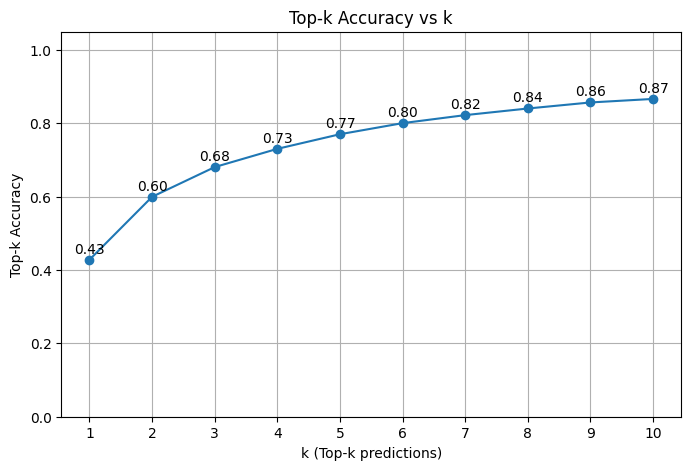

In [49]:
import numpy as np
import matplotlib.pyplot as plt


def plot_top_k_accuracy(clf, X, y, max_k=10):
    """
    Plot top-k accuracy for k = 1 to max_k with value labels on each point.
    """
    probs = clf.predict_proba(X)
    top_k_scores = []

    for k in range(1, max_k + 1):
        topk = np.argsort(probs, axis=1)[:, ::-1][:, :k]
        score = np.mean([y[i] in topk[i] for i in range(len(y))])
        top_k_scores.append(score)

    # Plot
    plt.figure(figsize=(8,5))
    plt.plot(range(1, max_k + 1), top_k_scores, marker='o', linestyle='-')

    # Add value labels above each point
    for i, score in enumerate(top_k_scores):
        plt.text(i + 1, score + 0.01, f"{score:.2f}", ha='center', va='bottom')

    plt.xticks(range(1, max_k + 1))
    plt.xlabel("k (Top-k predictions)")
    plt.ylabel("Top-k Accuracy")
    plt.title("Top-k Accuracy vs k")
    plt.ylim(0, 1.05)  # make sure labels fit
    plt.grid(True)
    print("Top-k accuracies:", top_k_scores)
    plt.show()
# Example:
plot_top_k_accuracy(clf, X_test, y_test, max_k=10)


In [41]:
from metrics import precision_recall_f1
from sklearn.metrics import classification_report

# predict (encoded labels)
y_pred_enc = clf.predict(X_test)

# Try to decode to original item names for readable metrics (falls back to encoded ints)
try:
    y_test_labels = le_y.inverse_transform(y_test)
    y_pred_labels = le_y.inverse_transform(y_pred_enc)
except Exception:
    y_test_labels = y_test
    y_pred_labels = y_pred_enc

# Print aggregated metrics
print('Weighted:', precision_recall_f1(y_test_labels, y_pred_labels, average='weighted'))
print('Macro: ', precision_recall_f1(y_test_labels, y_pred_labels, average='macro'))
print('Micro: ', precision_recall_f1(y_test_labels, y_pred_labels, average='micro'))

# Detailed per-class report (precision / recall / f1)
print('\nClassification report:\n')
print(classification_report(y_test_labels, y_pred_labels, digits=4))

# Show your top-k accuracies (keep your existing function)
try:
    print('Top-1:', top_k_accuracy(clf, X_test, y_test, k=1))
    print('Top-3:', top_k_accuracy(clf, X_test, y_test, k=3))
    print('Top-5:', top_k_accuracy(clf, X_test, y_test, k=5))
except Exception:
    pass


Weighted: {'precision': 0.41860194204622325, 'recall': 0.42781430954951416, 'f1': 0.4212925900335942}
Macro:  {'precision': 0.3338510743333645, 'recall': 0.3283351388183556, 'f1': 0.3280427211531806}
Micro:  {'precision': 0.42781430954951416, 'recall': 0.42781430954951416, 'f1': 0.42781430954951416}

Classification report:

                           precision    recall  f1-score   support

             Abyssal Mask     0.0588    0.0625    0.0606        16
        Archangel's Staff     0.5195    0.5128    0.5161        78
            Ardent Censer     0.3091    0.3269    0.3178        52
          Armored Advance     0.2706    0.2473    0.2584       186
                Axiom Arc     0.3804    0.4167    0.3977        84
           Banshee's Veil     0.0909    0.0357    0.0513        28
            Black Cleaver     0.3827    0.4189    0.4000       148
          Blackfire Torch     0.5584    0.6111    0.5836       180
 Blade of The Ruined King     0.5269    0.5131    0.5199       191
   

c:\Users\preda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\preda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\preda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

Top-1: 0.4281087447247031
Top-3: 0.6808322700952008
Top-5: 0.7704387084110315


In [42]:
from sklearn.metrics import precision_recall_fscore_support, classification_report

# Exemple pour un score global
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test_labels, y_pred_labels, average='weighted', zero_division=0
)

print("Weighted Precision:", precision)
print("Weighted Recall:", recall)
print("Weighted F1:", f1)

# Classification report propre
print(classification_report(
    y_test_labels, y_pred_labels, digits=4, zero_division=0
))


Weighted Precision: 0.41860194204622325
Weighted Recall: 0.42781430954951416
Weighted F1: 0.4212925900335942
                           precision    recall  f1-score   support

             Abyssal Mask     0.0588    0.0625    0.0606        16
        Archangel's Staff     0.5195    0.5128    0.5161        78
            Ardent Censer     0.3091    0.3269    0.3178        52
          Armored Advance     0.2706    0.2473    0.2584       186
                Axiom Arc     0.3804    0.4167    0.3977        84
           Banshee's Veil     0.0909    0.0357    0.0513        28
            Black Cleaver     0.3827    0.4189    0.4000       148
          Blackfire Torch     0.5584    0.6111    0.5836       180
 Blade of The Ruined King     0.5269    0.5131    0.5199       191
      Bloodletter's Curse     0.0000    0.0000    0.0000        19
            Bloodthirster     0.3182    0.2692    0.2917        78
      Chainlaced Crushers     0.2583    0.1987    0.2246       156
      Chempunk Chai

In [43]:
print("Top-1:", top_k_accuracy(clf, X_test, y_test, k=1))
print("Top-3:", top_k_accuracy(clf, X_test, y_test, k=3))
print("Top-5:", top_k_accuracy(clf, X_test, y_test, k=5))


Top-1: 0.4281087447247031
Top-3: 0.6808322700952008
Top-5: 0.7704387084110315


In [6]:
os.makedirs('models', exist_ok=True)
joblib.dump({'model': clf, 'preprocessor': preprocessor, 'label_encoder': le_y, 'feature_columns': FEATURE_COLS},
            'models/item_rf_pipeline.pkl')
print("Pipeline saved to models/item_rf_pipeline.pkl")

Pipeline saved to models/item_rf_pipeline.pkl


In [33]:
pipeline = {'model': clf, 'preprocessor': preprocessor, 'label_encoder': le_y, 'feature_columns': FEATURE_COLS}

def predict_topk_row(input_row, k=5, pipeline=pipeline):
    model = pipeline['model']
    preprocessor = pipeline['preprocessor']
    le = pipeline['label_encoder']
    feature_cols = pipeline['feature_columns']

    # Normalisation des valeurs manquantes
    row = {c: input_row.get(c, None) for c in feature_cols}
    row['Item actuel'] = row.get('Item actuel') or 'None'
    row['Role'] = row.get('Role') or 'Unknown'
    row['Adversaire'] = row.get('Adversaire') or 'Unknown'
    if row.get('Gold') is None:
        row['Gold'] = np.nan

    X = pd.DataFrame([row], columns=feature_cols)
    X_proc = preprocessor.transform(X)
    probs = model.predict_proba(X_proc)[0]
    top_idx = np.argsort(probs)[::-1][:k]
    top_items = le.inverse_transform(top_idx)
    top_probs = probs[top_idx]
    return list(zip(top_items, top_probs))

Transformed feature count: 480
num__Gold: 0.217839
cat__Item actuel_None: 0.019675
cat__Dégat de l'adversaire_AD: 0.010131
cat__Dégat de l'adversaire_AP: 0.009024
cat__Classe de l'adversaire_Fighter: 0.008958
cat__Classe de l'adversaire_Tank: 0.008409
cat__Classe de l'adversaire_Mage: 0.007830
cat__Classe de l'adversaire_Assassin: 0.007305
cat__Dégat du champion_AD: 0.006950
cat__Classe du champion_Tank: 0.006484
cat__Dégat de l'adversaire_Mixed: 0.006325
cat__Role_TOP: 0.006314
cat__Role_JUNGLE: 0.006206
cat__Item actuel_Kraken Slayer: 0.006082
cat__Item actuel_Trinity Force: 0.006013
cat__Role_MIDDLE: 0.005675
cat__Classe de l'adversaire_Marksman: 0.005641
cat__Role_UTILITY: 0.005518
cat__Dégat du champion_AP: 0.005424
cat__Classe du champion_Fighter: 0.004820
cat__Item actuel_Liandry's Torment: 0.004457
cat__Classe de l'adversaire_Support: 0.004393
cat__Classe du champion_Marksman: 0.004325
cat__Item actuel_Blade of The Ruined King: 0.004317
cat__Item actuel_Crimson Lucidity: 0.0043

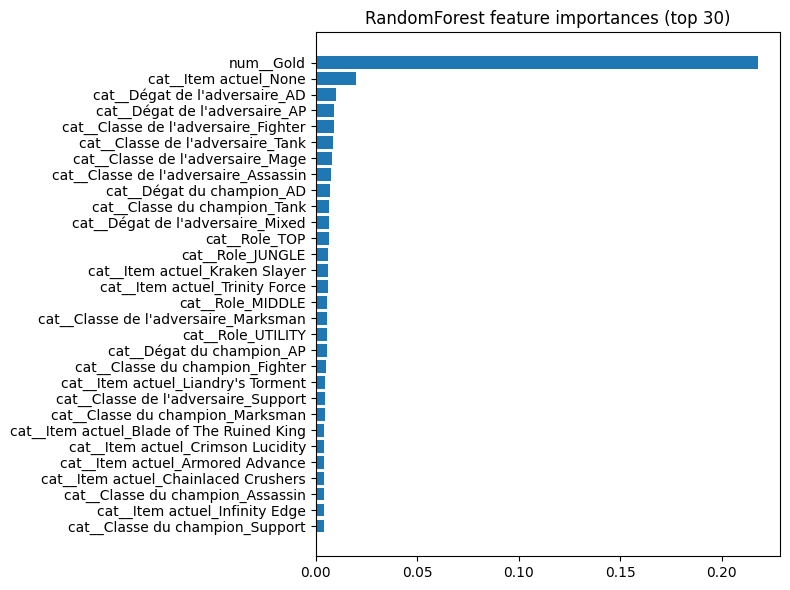


Aggregated importances by original column:
cat    0.782161
num    0.217839
dtype: float64


PicklingError: Could not pickle the task to send it to the workers.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.inspection import permutation_importance

# 1) helper to get transformed feature names from ColumnTransformer
def get_feature_names(column_transformer):
    try:
        return list(column_transformer.get_feature_names_out())
    except Exception:
        names = []
        for name, trans, cols in column_transformer.transformers_:
            if trans == 'drop': 
                continue
            if hasattr(trans, "get_feature_names_out"):
                # e.g. OneHotEncoder, Pipelines may expose this
                try:
                    out = trans.get_feature_names_out(cols)
                except Exception:
                    out = trans.get_feature_names_out()
                names.extend(list(out))
            else:
                # fallback: OneHotEncoder stores categories_ after fit
                if hasattr(trans, "categories_"):
                    for col, cats in zip(cols, trans.categories_):
                        names += [f"{col}__{c}" for c in cats]
                else:
                    names += list(cols)
        return names

feature_names = get_feature_names(preprocessor)
print("Transformed feature count:", len(feature_names))

# 2) tree-based importances (fast)
importances = clf.feature_importances_
order = np.argsort(importances)[::-1]

top_n = 20
for i in order[:top_n]:
    print(f"{feature_names[i]}: {importances[i]:.6f}")

# optional: plot top importances
plt.figure(figsize=(8,6))
plt.barh([feature_names[i] for i in order[:top_n]][::-1],
         importances[order[:top_n]][::-1])
plt.title("RandomForest feature importances (top %d)"%top_n)
plt.tight_layout()
plt.show()

# 3) aggregate one-hot importances back to original columns
agg = defaultdict(float)
for name, imp in zip(feature_names, importances):
    base = name.split("__")[0] if "__" in name else name
    agg[base] += imp

agg_df = pd.Series(agg).sort_values(ascending=False)
print("\nAggregated importances by original column:")
print(agg_df.head(20))

# 4) permutation importance (more reliable but slower)
r = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
perm_order = r.importances_mean.argsort()[::-1]
print("\nPermutation importances (top):")
for i in perm_order[:top_n]:
    print(f"{feature_names[i]}: mean={r.importances_mean[i]:.6f} std={r.importances_std[i]:.6f}")

In [34]:
# Exemple (à chaque fois bien préciser toutes les features demandées) :

ex1 = {"Champion":"Aatrox","Classe du champion":"Fighter","Dégat du champion":"AD","Role":"TOP","Adversaire":"Renekton","Classe de l'adversaire":"Fighter","Dégat de l'adversaire":"AD","Item actuel":"None","Gold":1200}
print("ex1 :",predict_topk_row(ex1, k=5))

ex2 = {"Champion":"Aatrox","Classe du champion":"Fighter","Dégat du champion":"AD","Role":"TOP","Adversaire":"Renekton","Classe de l'adversaire":"Fighter","Dégat de l'adversaire":"AD","Item actuel":"Spear of Shojin","Gold":1200}
print("ex2 :",predict_topk_row(ex2, k=5))

ex3 = {"Champion":"Aatrox","Classe du champion":"Fighter","Dégat du champion":"AD","Role":"TOP","Adversaire":"Renekton","Classe de l'adversaire":"Fighter","Dégat de l'adversaire":"AD","Item actuel":"Sundered Sky","Gold":1200}
print("ex3 :",predict_topk_row(ex3, k=5))

"""
ex1 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"None","Gold":1200}
print("ex1 :",predict_topk_row(ex1, k=5))

ex2 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"Spear of Shojin","Gold":1200}
print("ex2 :",predict_topk_row(ex2, k=5))

ex3 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"Sundered Sky","Gold":1200}
print("ex3 :",predict_topk_row(ex3, k=5)) """

ex1 : [('Spear of Shojin', 0.36), ('Eclipse', 0.275), ('Black Cleaver', 0.085), ('Sundered Sky', 0.085), ('Trinity Force', 0.06)]
ex2 : [('Voltaic Cyclosword', 0.465), ('Spear of Shojin', 0.12), ('Eclipse', 0.095), ('Sundered Sky', 0.075), ('Black Cleaver', 0.045)]
ex3 : [('Spear of Shojin', 0.305), ('Voltaic Cyclosword', 0.195), ('Eclipse', 0.095), ('Armored Advance', 0.095), ('Sundered Sky', 0.075)]


'\nex1 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"None","Gold":1200}\nprint("ex1 :",predict_topk_row(ex1, k=5))\n\nex2 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"Spear of Shojin","Gold":1200}\nprint("ex2 :",predict_topk_row(ex2, k=5))\n\nex3 = {"Champion":"Aatrox","Role":"TOP","Adversaire":"Renekton","Item actuel":"Sundered Sky","Gold":1200}\nprint("ex3 :",predict_topk_row(ex3, k=5)) '